In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv('/content/comprehensive_mutual_funds_data.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 814
Number of columns: 20


In [4]:
df.head()

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,0.01,0.24,3,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,6.9
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,0.56,1.1,1,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,0.67,1.42,5,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,9.7
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,NaN
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7


In [5]:
for column in df.columns:
  print(column)

scheme_name
min_sip
min_lumpsum
expense_ratio
fund_size_cr
fund_age_yr
fund_manager
sortino
alpha
sd
beta
sharpe
risk_level
amc_name
rating
category
sub_category
returns_1yr
returns_3yr
returns_5yr


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 814 entries, 0 to 813
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   scheme_name    814 non-null    object 
 1   min_sip        814 non-null    int64  
 2   min_lumpsum    814 non-null    int64  
 3   expense_ratio  814 non-null    float64
 4   fund_size_cr   814 non-null    float64
 5   fund_age_yr    814 non-null    int64  
 6   fund_manager   814 non-null    object 
 7   sortino        814 non-null    object 
 8   alpha          814 non-null    object 
 9   sd             814 non-null    object 
 10  beta           814 non-null    object 
 11  sharpe         814 non-null    object 
 12  risk_level     814 non-null    int64  
 13  amc_name       814 non-null    object 
 14  rating         814 non-null    int64  
 15  category       814 non-null    object 
 16  sub_category   814 non-null    object 
 17  returns_1yr    814 non-null    float64
 18  returns_3y

In [7]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
scheme_name        0
min_sip            0
min_lumpsum        0
expense_ratio      0
fund_size_cr       0
fund_age_yr        0
fund_manager       0
sortino            0
alpha              0
sd                 0
beta               0
sharpe             0
risk_level         0
amc_name           0
rating             0
category           0
sub_category       0
returns_1yr        0
returns_3yr       21
returns_5yr      167
dtype: int64


In [8]:
missing_report = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_report = missing_report[missing_report['Missing Count'] > 0]

print(missing_report)


             Missing Count  Missing Percentage
returns_3yr             21            2.579853
returns_5yr            167           20.515971


In [9]:
for column in df.columns:
    dash_count = df[column].astype(str).str.strip().eq('-').sum()

    if dash_count > 0:
        print(column, ":", dash_count, "dash values")


sortino : 23 dash values
alpha : 42 dash values
sd : 24 dash values
beta : 42 dash values
sharpe : 23 dash values


In [10]:
duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)


Number of exact duplicate rows: 0


In [11]:
df[df.duplicated(keep=False)]

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr


In [12]:
print(df.dtypes)

scheme_name       object
min_sip            int64
min_lumpsum        int64
expense_ratio    float64
fund_size_cr     float64
fund_age_yr        int64
fund_manager      object
sortino           object
alpha             object
sd                object
beta              object
sharpe            object
risk_level         int64
amc_name          object
rating             int64
category          object
sub_category      object
returns_1yr      float64
returns_3yr      float64
returns_5yr      float64
dtype: object


In [13]:
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)
print("Cleaning copy created successfully!")


Original dataset shape: (814, 20)
Working dataset shape: (814, 20)
Cleaning copy created successfully!


In [14]:
df_clean = df_clean.replace(
    ['-', '–', '—', ''],
    np.nan
)

print("Dash placeholders replaced successfully!")


Dash placeholders replaced successfully!


In [15]:
numeric_columns = [
    'min_sip',
    'min_lumpsum',
    'expense_ratio',
    'fund_size_cr',
    'fund_age_yr',
    'sortino',
    'alpha',
    'sd',
    'beta',
    'sharpe',
    'risk_level',
    'rating',
    'returns_1yr',
    'returns_3yr',
    'returns_5yr'
]

# Keep only columns that actually exist
numeric_columns = [
    col for col in numeric_columns if col in df_clean.columns
]

# Convert each selected column
for col in numeric_columns:

    df_clean[col] = (
        df_clean[col]
        .astype('string')
        .str.strip()
        .str.replace(',', '', regex=False)
        .str.replace('₹', '', regex=False)
        .str.replace('%', '', regex=False)
    )

    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors='coerce'
    )

print("Numerical columns standardised!")


Numerical columns standardised!


In [16]:
print(df_clean[numeric_columns].dtypes)


min_sip            Int64
min_lumpsum        Int64
expense_ratio    Float64
fund_size_cr     Float64
fund_age_yr        Int64
sortino          Float64
alpha            Float64
sd               Float64
beta             Float64
sharpe           Float64
risk_level         Int64
rating             Int64
returns_1yr      Float64
returns_3yr      Float64
returns_5yr      Float64
dtype: object


In [17]:
print("Missing values after cleaning:")

print(df_clean[numeric_columns].isnull().sum())


Missing values after cleaning:
min_sip            0
min_lumpsum        0
expense_ratio      0
fund_size_cr       0
fund_age_yr        0
sortino           23
alpha             42
sd                24
beta              42
sharpe            23
risk_level         0
rating             0
returns_1yr        0
returns_3yr       21
returns_5yr      167
dtype: int64


In [18]:
before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates()

after_duplicates = len(df_clean)

removed_duplicates = before_duplicates - after_duplicates

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates:", after_duplicates)
print("Exact duplicate rows removed:", removed_duplicates)

Rows before removing duplicates: 814
Rows after removing duplicates: 814
Exact duplicate rows removed: 0


In [19]:
print("Cleaned dataset shape:", df_clean.shape)

display(df_clean.head())

print("\nFinal data types:")
print(df_clean.dtypes)


Cleaned dataset shape: (814, 20)


,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,0.01,0.24,3,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,6.9
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,0.56,1.1,1,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,0.67,1.42,5,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,9.7
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,<NA>
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7



Final data types:
scheme_name       object
min_sip            Int64
min_lumpsum        Int64
expense_ratio    Float64
fund_size_cr     Float64
fund_age_yr        Int64
fund_manager      object
sortino          Float64
alpha            Float64
sd               Float64
beta             Float64
sharpe           Float64
risk_level         Int64
amc_name          object
rating             Int64
category          object
sub_category      object
returns_1yr      Float64
returns_3yr      Float64
returns_5yr      Float64
dtype: object


In [20]:
df_clean.to_csv(
    '/content/mutual_fund_cleaned.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [21]:

# STEP 5.1: Statistical summary

# Select important numerical columns
analysis_columns = [
    'min_sip',
    'min_lumpsum',
    'expense_ratio',
    'fund_size_cr',
    'fund_age_yr',
    'returns_1yr',
    'returns_3yr',
    'returns_5yr',
    'sd',
    'sharpe',
    'sortino',
    'alpha',
    'beta'
]

# Keep columns available in the dataset
analysis_columns = [
    col for col in analysis_columns if col in df_clean.columns
]

# Calculate statistical summary
summary = df_clean[analysis_columns].describe().T

print("STATISTICAL SUMMARY")
display(summary)


STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
min_sip,814.0,528.5,369.184517,0.0,150.0,500.0,1000.0,2000.0
min_lumpsum,814.0,3047.468059,2514.619513,0.0,500.0,5000.0,5000.0,25000.0
expense_ratio,814.0,0.713231,0.482161,0.0,0.31,0.615,1.03,2.59
fund_size_cr,814.0,3812.854214,7181.479475,2.38,175.25,940.5,3819.0,57052.0
fund_age_yr,814.0,8.31941,2.640622,1.0,6.0,10.0,10.0,17.0
returns_1yr,814.0,3.921376,6.675502,-19.7,1.5,4.4,5.6,130.8
returns_3yr,793.0,18.525347,12.108476,3.3,6.2,18.5,27.1,71.4
returns_5yr,647.0,9.490726,3.714015,-4.1,6.7,8.9,12.2,23.2
sd,790.0,10.272696,7.805667,0.27,2.1625,12.3,16.4375,77.72
sharpe,791.0,1.204185,0.536431,-0.82,0.93,1.29,1.55,3.52


In [22]:
for column in analysis_columns:

    modes = df_clean[column].mode()

    print("\nColumn:", column)

    if len(modes) > 0:
        print("Mode:", modes.tolist())
    else:
        print("No mode available")



Column: min_sip
Mode: [500]

Column: min_lumpsum
Mode: [5000]

Column: expense_ratio
Mode: [0.21]

Column: fund_size_cr
Mode: [90.0]

Column: fund_age_yr
Mode: [10]

Column: returns_1yr
Mode: [5.6]

Column: returns_3yr
Mode: [3.9]

Column: returns_5yr
Mode: [5.3]

Column: sd
Mode: [0.38]

Column: sharpe
Mode: [1.4]

Column: sortino
Mode: [3.24, 3.44]

Column: alpha
Mode: [0.67]

Column: beta
Mode: [0.94]


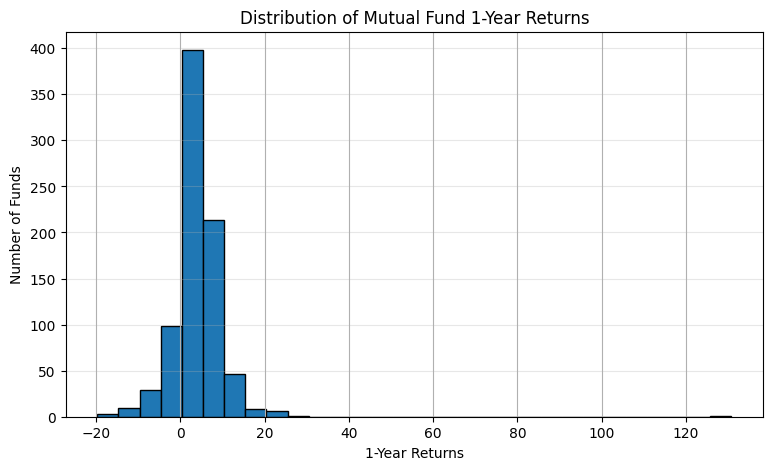

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

df_clean['returns_1yr'].dropna().hist(
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Mutual Fund 1-Year Returns')
plt.xlabel('1-Year Returns')
plt.ylabel('Number of Funds')

plt.grid(axis='y', alpha=0.3)
plt.show()


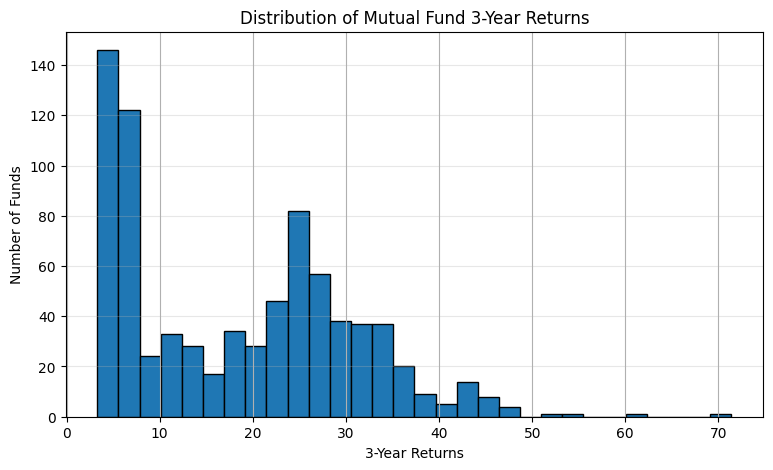

In [24]:
plt.figure(figsize=(9, 5))

df_clean['returns_3yr'].dropna().hist(
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Mutual Fund 3-Year Returns')
plt.xlabel('3-Year Returns')
plt.ylabel('Number of Funds')

plt.grid(axis='y', alpha=0.3)
plt.show()


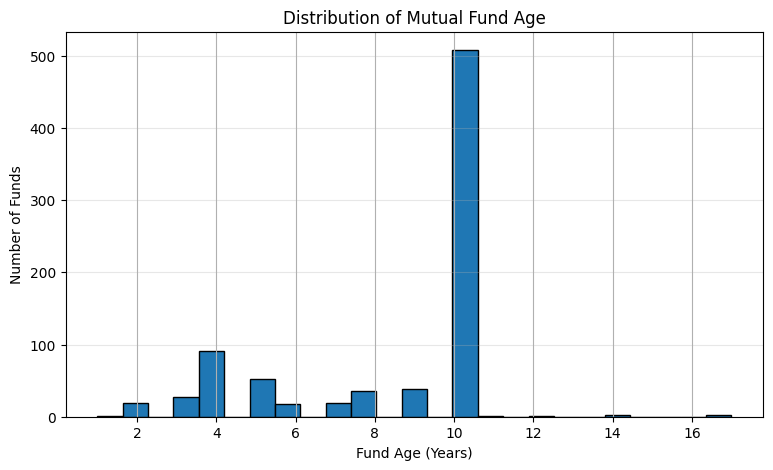

In [25]:
plt.figure(figsize=(9, 5))

df_clean['fund_age_yr'].dropna().hist(
    bins=25,
    edgecolor='black'
)

plt.title('Distribution of Mutual Fund Age')
plt.xlabel('Fund Age (Years)')
plt.ylabel('Number of Funds')

plt.grid(axis='y', alpha=0.3)
plt.show()


Risk-level counts:
risk_level
1     53
2    127
3    124
4     65
5     27
6    418
Name: count, dtype: Int64


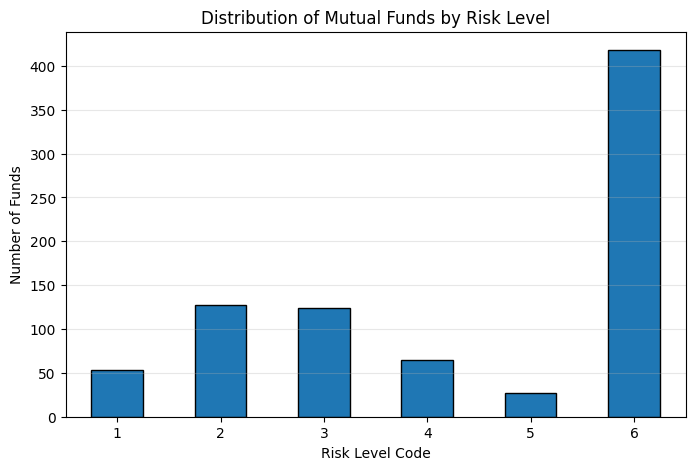

In [26]:

# STEP 5.6: Risk-level distribution

risk_counts = df_clean['risk_level'].value_counts().sort_index()

print("Risk-level counts:")
print(risk_counts)

plt.figure(figsize=(8, 5))

risk_counts.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribution of Mutual Funds by Risk Level')
plt.xlabel('Risk Level Code')
plt.ylabel('Number of Funds')

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()


In [27]:

# STEP 5.7: Detect outliers using IQR

outlier_columns = [
    'returns_1yr',
    'returns_3yr',
    'returns_5yr',
    'expense_ratio',
    'fund_age_yr',
    'fund_size_cr'
]

outlier_columns = [
    col for col in outlier_columns if col in df_clean.columns
]

for column in outlier_columns:

    data = df_clean[column].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    print("\nColumn:", column)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))



Column: returns_1yr
Lower Bound: -4.6499999999999995
Upper Bound: 11.75
Number of Outliers: 87

Column: returns_3yr
Lower Bound: -25.150000000000002
Upper Bound: 58.45
Number of Outliers: 2

Column: returns_5yr
Lower Bound: -1.549999999999998
Upper Bound: 20.449999999999996
Number of Outliers: 10

Column: expense_ratio
Lower Bound: -0.77
Upper Bound: 2.1100000000000003
Number of Outliers: 4

Column: fund_age_yr
Lower Bound: 0.0
Upper Bound: 16.0
Number of Outliers: 2

Column: fund_size_cr
Lower Bound: -5290.375
Upper Bound: 9284.625
Number of Outliers: 94


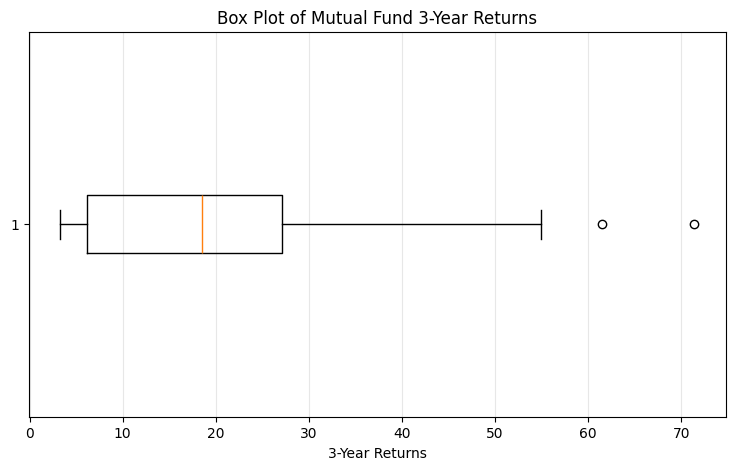

In [28]:

# STEP 5.8: Box plot of 3-year returns

plt.figure(figsize=(9, 5))

plt.boxplot(
    df_clean['returns_3yr'].dropna(),
    vert=False
)

plt.title('Box Plot of Mutual Fund 3-Year Returns')
plt.xlabel('3-Year Returns')

plt.grid(axis='x', alpha=0.3)
plt.show()


In [29]:
from sklearn.preprocessing import MinMaxScaler

print("MinMaxScaler imported successfully!")

MinMaxScaler imported successfully!


In [30]:
# Select numerical columns for normalization

scale_columns = [
    'returns_1yr',
    'returns_3yr',
    'returns_5yr',
    'expense_ratio',
    'fund_age_yr',
    'fund_size_cr',
    'sd',
    'sharpe',
    'sortino',
    'alpha',
    'beta'
]

# Keep only columns available in the dataset
scale_columns = [
    col for col in scale_columns
    if col in df_clean.columns
]

print("Columns selected for normalization:")
print(scale_columns)

Columns selected for normalization:
['returns_1yr', 'returns_3yr', 'returns_5yr', 'expense_ratio', 'fund_age_yr', 'fund_size_cr', 'sd', 'sharpe', 'sortino', 'alpha', 'beta']


In [31]:
# Create a separate copy of the cleaned dataset

df_scaled = df_clean.copy()

# Create the MinMaxScaler object

scaler = MinMaxScaler()

# Apply normalization

df_scaled_columns = scaler.fit_transform(
    df_clean[scale_columns]
)

# Store normalized values in new columns

for i, col in enumerate(scale_columns):
    df_scaled[col + '_scaled'] = df_scaled_columns[:, i]

print("Normalization completed successfully!")

Normalization completed successfully!


In [32]:
# Compare original and scaled values

comparison = df_scaled[
    [
        'returns_3yr',
        'returns_3yr_scaled',
        'expense_ratio',
        'expense_ratio_scaled'
    ]
]

print(comparison.head(10))

   returns_3yr  returns_3yr_scaled  expense_ratio  expense_ratio_scaled
0          6.5            0.046990           0.27              0.104247
1          4.8            0.022026           0.36              0.138996
2         18.9            0.229075           0.53              0.204633
3         17.1            0.202643           0.76              0.293436
4         18.6            0.224670           0.61              0.235521
5         24.6            0.312775           1.17              0.451737
6          6.8            0.051395           0.37              0.142857
7         29.4            0.383260           1.29              0.498069
8          7.1            0.055800           0.31              0.119691
9          9.0            0.083700           0.69              0.266409


In [33]:
# Check minimum and maximum scaled values

scaled_columns = [
    col + '_scaled' for col in scale_columns
]

print(df_scaled[scaled_columns].agg(['min', 'max']).T)

                      min  max
returns_1yr_scaled    0.0  1.0
returns_3yr_scaled    0.0  1.0
returns_5yr_scaled    0.0  1.0
expense_ratio_scaled  0.0  1.0
fund_age_yr_scaled    0.0  1.0
fund_size_cr_scaled   0.0  1.0
sd_scaled             0.0  1.0
sharpe_scaled         0.0  1.0
sortino_scaled        0.0  1.0
alpha_scaled          0.0  1.0
beta_scaled           0.0  1.0


In [34]:
# Save normalized dataset

df_scaled.to_csv(
    '/content/mutual_fund_normalized.csv',
    index=False
)

print("Normalized dataset saved successfully!")

Normalized dataset saved successfully!


In [35]:
returns_score = df_scaled['returns_3yr_scaled']

In [36]:
# Create a separate dataset for scoring

df_scored = df_scaled.copy()

# Select the columns required for scoring

required_columns = [
    'returns_3yr_scaled',
    'expense_ratio_scaled',
    'fund_age_yr',
    'returns_1yr'
]

# Check whether all required columns exist

print(df_scored[required_columns].isnull().sum())

returns_3yr_scaled      21
expense_ratio_scaled     0
fund_age_yr              0
returns_1yr              0
dtype: int64


In [37]:
# Keep funds with complete information for all four scoring factors

df_scored = df_scored.dropna(
    subset=required_columns
).copy()

print("Funds available for scoring:", len(df_scored))

Funds available for scoring: 793


In [38]:
# 1. Three-year returns score

df_scored['returns_score'] = (
    df_scored['returns_3yr_scaled']
)

# 2. Expense ratio score
# Lower expense ratio receives a higher score

df_scored['expense_score'] = (
    1 - df_scored['expense_ratio_scaled']
)

# 3. Fund age score
# Preferred fund age = 10 years

df_scored['age_score'] = (
    1 - abs(df_scored['fund_age_yr'] - 10) / 10
).clip(0, 1)

# 4. Consistency score
# Positive 1-year return = 1, otherwise = 0

df_scored['consistency_score'] = (
    df_scored['returns_1yr'] > 0
).astype(int)

print("All four individual scores calculated!")

All four individual scores calculated!


In [39]:
# Calculate final mutual fund score

df_scored['final_score'] = (
    0.40 * df_scored['returns_score'] +
    0.25 * df_scored['expense_score'] +
    0.20 * df_scored['age_score'] +
    0.15 * df_scored['consistency_score']
)

print("Final scores calculated successfully!")

Final scores calculated successfully!


In [40]:
# Sort funds by final score in descending order

df_ranked = df_scored.sort_values(
    by='final_score',
    ascending=False
).copy()

# Assign ranks

df_ranked['rank'] = range(
    1, len(df_ranked) + 1
)

print("Mutual fund ranking completed!")

Mutual fund ranking completed!


In [41]:
# Display Top 10 funds

top_10 = df_ranked[
    [
        'rank',
        'scheme_name',
        'returns_3yr',
        'expense_ratio',
        'fund_age_yr',
        'returns_1yr',
        'final_score'
    ]
].head(10)

top_10

,rank,scheme_name,returns_3yr,expense_ratio,fund_age_yr,returns_1yr,final_score
608,1,Quant Small Cap Fund,71.4,0.64,10,5.4,0.938224
603,2,Quant Infrastructure Fund,61.5,0.64,10,5.6,0.880074
609,3,Quant Tax Plan- Direct Growth,54.9,0.57,10,0.9,0.848064
601,4,Quant Flexi Cap Fund,47.7,0.58,10,6.8,0.804808
600,5,Quant Active Fund,45.5,0.58,10,1.0,0.791886
606,6,Quant Mid Cap Fund,45.1,0.63,10,8.8,0.78471
571,7,Nippon India Small Cap Fund,47.6,0.86,10,8.7,0.777194
607,8,Quant Multi Asset Fund,42.6,0.56,10,10.6,0.776783
594,9,PGIM India Midcap Opportunities Fund,42.9,0.46,9,2.0,0.768198
348,10,ICICI Pru Thematic Advantage Fund,35.4,0.25,10,5.4,0.764415


In [42]:
# Export the complete ranked dataset

df_ranked.to_csv(
    '/content/mutual_fund_ranked.csv',
    index=False
)

print("Ranked dataset saved successfully!")

Ranked dataset saved successfully!


In [43]:
# STEP 8: Extract the Top 30 mutual funds

top_30 = (
    df_scored
    .sort_values(by='final_score', ascending=False)
    .head(30)
    .copy()
)

# Reset the index for a clean table
top_30 = top_30.reset_index(drop=True)

# Display the Top 30
display(top_30)

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,...,sd_scaled,sharpe_scaled,sortino_scaled,alpha_scaled,beta_scaled,returns_score,expense_score,age_score,consistency_score,final_score
0,Quant Small Cap Fund,1000,5000,0.64,3301.0,10,Sanjeev Sharma,3.71,19.16,24.75,...,0.316075,0.675115,0.382148,0.800985,0.881643,1.000000,0.752896,1.0,1,0.938224
1,Quant Infrastructure Fund,1000,5000,0.64,822.0,10,Vasav Sahgal,3.44,27.24,19.24,...,0.244932,0.718894,0.363319,1.000000,0.869297,0.854626,0.752896,1.0,1,0.880074
2,Quant Tax Plan- Direct Growth,500,500,0.57,2779.0,10,Vasav Sahgal,3.5,17.63,19.74,...,0.251388,0.656682,0.367503,0.763300,0.880837,0.757709,0.779923,1.0,1,0.848064
3,Quant Flexi Cap Fund,1000,5000,0.58,1044.0,10,Vasav Sahgal,3.65,15.93,19.16,...,0.243899,0.635945,0.377964,0.721429,0.879495,0.651982,0.776062,1.0,1,0.804808
4,Quant Active Fund,1000,5000,0.58,3531.0,10,Sanjeev Sharma,3.33,13.82,19.65,...,0.250226,0.619816,0.355649,0.669458,0.881106,0.619677,0.776062,1.0,1,0.791886
5,Quant Mid Cap Fund,1000,5000,0.63,1550.0,10,Sanjeev Sharma,3.58,11.21,18.73,...,0.238347,0.638249,0.373082,0.605172,0.878154,0.613803,0.756757,1.0,1,0.78471
6,Nippon India Small Cap Fund,100,5000,0.86,23910.0,10,Samir Rachh,4.2,10.01,19.31,...,0.245836,0.663594,0.416318,0.575616,0.878959,0.650514,0.667954,1.0,1,0.777194
7,Quant Multi Asset Fund,1000,5000,0.56,634.0,10,Vasav Sahgal,3.23,19.52,18.63,...,0.237056,0.601382,0.348675,0.809852,0.875201,0.577093,0.783784,1.0,1,0.776783
8,PGIM India Midcap Opportunities Fund,1000,5000,0.46,7707.0,9,Aniruddha Naha,4.61,6.9,18.52,...,0.235636,0.631336,0.444909,0.499015,0.881106,0.581498,0.822394,0.9,1,0.768198
9,ICICI Pru Thematic Advantage Fund,1000,5000,0.25,958.0,10,Dharmesh Kakkad,4.13,6.63,18.22,...,0.231762,0.564516,0.411437,0.492365,0.881374,0.471366,0.903475,1.0,1,0.764415


In [44]:
# Select important columns for the Excel report

excel_columns = [
    'rank',
    'scheme_name',
    'category',
    'sub_category',
    'amc_name',
    'fund_manager',
    'returns_1yr',
    'returns_3yr',
    'expense_ratio',
    'fund_age_yr',
    'fund_size_cr',
    'risk_level',
    'rating',
    'final_score'
]

# Keep only columns available in the dataset
excel_columns = [
    col for col in excel_columns
    if col in top_30.columns
]

top_30_excel = top_30[excel_columns].copy()

display(top_30_excel)

,scheme_name,category,sub_category,amc_name,fund_manager,returns_1yr,returns_3yr,expense_ratio,fund_age_yr,fund_size_cr,risk_level,rating,final_score
0,Quant Small Cap Fund,Equity,Small Cap Mutual Funds,Quant Mutual Fund,Sanjeev Sharma,5.4,71.4,0.64,10,3301.0,6,5,0.938224
1,Quant Infrastructure Fund,Equity,Sectoral / Thematic Mutual Funds,Quant Mutual Fund,Vasav Sahgal,5.6,61.5,0.64,10,822.0,6,5,0.880074
2,Quant Tax Plan- Direct Growth,Equity,ELSS Mutual Funds,Quant Mutual Fund,Vasav Sahgal,0.9,54.9,0.57,10,2779.0,6,5,0.848064
3,Quant Flexi Cap Fund,Equity,Flexi Cap Funds,Quant Mutual Fund,Vasav Sahgal,6.8,47.7,0.58,10,1044.0,6,5,0.804808
4,Quant Active Fund,Equity,Multi Cap Funds,Quant Mutual Fund,Sanjeev Sharma,1.0,45.5,0.58,10,3531.0,6,0,0.791886
5,Quant Mid Cap Fund,Equity,Mid Cap Mutual Funds,Quant Mutual Fund,Sanjeev Sharma,8.8,45.1,0.63,10,1550.0,6,5,0.78471
6,Nippon India Small Cap Fund,Equity,Small Cap Mutual Funds,Nippon India Mutual Fund,Samir Rachh,8.7,47.6,0.86,10,23910.0,6,4,0.777194
7,Quant Multi Asset Fund,Hybrid,Multi Asset Allocation Mutual Funds,Quant Mutual Fund,Vasav Sahgal,10.6,42.6,0.56,10,634.0,6,5,0.776783
8,PGIM India Midcap Opportunities Fund,Equity,Mid Cap Mutual Funds,PGIM India Mutual Fund,Aniruddha Naha,2.0,42.9,0.46,9,7707.0,6,5,0.768198
9,ICICI Pru Thematic Advantage Fund,Other,FoFs Domestic,ICICI Prudential Mutual Fund,Dharmesh Kakkad,5.4,35.4,0.25,10,958.0,6,0,0.764415


In [45]:
# Export Top 30 funds to Excel

file_path = '/content/Top_30_Mutual_Funds.xlsx'

top_30_excel.to_excel(
    file_path,
    sheet_name='Top 30 Funds',
    index=False
)

print("Excel file created successfully!")

Excel file created successfully!


In [46]:
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

# Open the Excel workbook
workbook = load_workbook(file_path)

# Select the Top 30 sheet
worksheet = workbook['Top 30 Funds']

# Format header row
for cell in worksheet[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill(
        start_color="1F4E78",
        end_color="1F4E78",
        fill_type="solid"
    )
    cell.alignment = Alignment(
        horizontal="center",
        vertical="center"
    )

# Freeze the header row
worksheet.freeze_panes = "A2"

# Add filters
worksheet.auto_filter.ref = worksheet.dimensions

# Adjust column widths
for column_cells in worksheet.columns:
    max_length = 0
    column_letter = get_column_letter(
        column_cells[0].column
    )

    for cell in column_cells:
        if cell.value is not None:
            max_length = max(
                max_length,
                len(str(cell.value))
            )

    worksheet.column_dimensions[column_letter].width = min(
        max_length + 3, 35
    )

# Format numeric values
for column_cells in worksheet.columns:
    header = str(column_cells[0].value)

    if header in [
        'returns_1yr',
        'returns_3yr',
        'expense_ratio',
        'final_score'
    ]:
        for cell in column_cells[1:]:
            cell.number_format = '0.00'

    if header == 'fund_size_cr':
        for cell in column_cells[1:]:
            cell.number_format = '#,##0.00'

# Save changes
workbook.save(file_path)

print("Excel formatting completed!")

Excel formatting completed!


In [47]:
# Common categories among the Top 30
print("Top Categories:")
display(
    top_30['category'].value_counts().reset_index()
)

# Common AMCs among the Top 30
print("Top AMCs:")
display(
    top_30['amc_name'].value_counts().reset_index()
)

# Risk-level code distribution
print("Risk Level Codes:")
display(
    top_30['risk_level'].value_counts().sort_index().reset_index()
)

Top Categories:


,category,count
0,Equity,24
1,Hybrid,3
2,Other,3


Top AMCs:


,amc_name,count
0,Quant Mutual Fund,10
1,ICICI Prudential Mutual Fund,5
2,HDFC Mutual Fund,2
3,Navi Mutual Fund,2
4,SBI Mutual Fund,2
5,Kotak Mahindra Mutual Fund,2
6,PGIM India Mutual Fund,1
7,Nippon India Mutual Fund,1
8,HSBC Mutual Fund,1
9,Sundaram Mutual Fund,1


Risk Level Codes:


,risk_level,count
0,6,30


In [48]:
# Select the Rank 1 fund
best_fund = top_30.iloc[0]

print("Fund Name:", best_fund["scheme_name"])
print("Rank:", 1)  # Since it is the first element in our sorted list
print("3-Year Returns:", best_fund["returns_3yr"])
print("1-Year Returns:", best_fund["returns_1yr"])
print("Expense Ratio:", best_fund["expense_ratio"])
print("Fund Age:", best_fund["fund_age_yr"])
print("Final Score:", best_fund["final_score"])

Fund Name: Quant Small Cap Fund
Rank: 1
3-Year Returns: 71.4
1-Year Returns: 5.4
Expense Ratio: 0.64
Fund Age: 10
Final Score: 0.9382239382239382


In [49]:
# STEP 9: Prepare data for Power BI

powerbi_data = df_clean.copy()

# Add the original row index to preserve scheme records
powerbi_data['original_index'] = powerbi_data.index

# Attach rank and final score from df_ranked (which contains the 'rank' column)
ranking_info = df_ranked[
    ['rank', 'final_score']
].copy()

powerbi_data = powerbi_data.join(ranking_info, how='left')

# Check the dataset
print("Power BI Dataset Shape:", powerbi_data.shape)

display(powerbi_data.head())

Power BI Dataset Shape: (814, 23)


,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,...,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr,original_index,rank,final_score
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,...,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,6.9,0,265.0,0.592734
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,...,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5,1,414.0,0.574062
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,...,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,9.7,2,146.0,0.640472
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,...,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,<NA>,3,781.0,0.337698
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,...,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7,4,168.0,0.630988


In [50]:
# Export the full dataset for Power BI

powerbi_data.to_csv(
    '/content/Mutual_Fund_PowerBI_Data.csv',
    index=False
)

print("Power BI dataset exported successfully!")

Power BI dataset exported successfully!


In [51]:
print("Categories:")
display(
    df_clean['category'].value_counts(dropna=False)
)

print("Sub-categories:")
display(
    df_clean['sub_category'].value_counts(dropna=False)
)

Categories:


,count
category,
Equity,308
Debt,282
Hybrid,116
Other,80
Solution Oriented,28


Sub-categories:


,count
sub_category,
Sectoral / Thematic Mutual Funds,82
ELSS Mutual Funds,52
FoFs Domestic,35
Liquid Mutual Funds,34
Aggressive Hybrid Mutual Funds,30
Index Funds,30
Large Cap Mutual Funds,28
Overnight Mutual Funds,26
Ultra Short Duration Funds,25


In [52]:

# STEP 13: FINAL INSIGHTS

# 1. Fund category with the highest total AUM
aum_by_category = (
    df_clean.groupby("category")["fund_size_cr"]
    .sum()
    .sort_values(ascending=False)
)

print("1. AUM BY CATEGORY")
print(aum_by_category)
print("Highest AUM category:", aum_by_category.index[0])
print("Highest total AUM:", round(aum_by_category.iloc[0], 2), "crore")


# 2. Fund manager with the highest total AUM
aum_by_manager = (
    df_clean.dropna(subset=["fund_manager", "fund_size_cr"])
    .groupby("fund_manager")["fund_size_cr"]
    .sum()
    .sort_values(ascending=False)
)

print("\n2. FUND MANAGER WITH HIGHEST AUM")
print(aum_by_manager.head(10))


# 3. Lowest average expense ratio by sub-category
expense_by_subcategory = (
    df_clean.groupby("sub_category")["expense_ratio"]
    .mean()
    .dropna()
    .sort_values()
)

print("\n3. LOWEST AVERAGE EXPENSE RATIO")
print(expense_by_subcategory.head(10))


# 4. Scheme with the highest 1-year return
best_1yr = df_clean.loc[
    df_clean["returns_1yr"].idxmax()
]

print("\n4. BEST 1-YEAR RETURN")
print("Scheme:", best_1yr["scheme_name"])
print("Return:", best_1yr["returns_1yr"], "%")


# 5. Average SIP and typical minimum lumpsum
average_sip = df_clean["min_sip"].mean()
median_lumpsum = df_clean["min_lumpsum"].median()

print("\n5. SIP AND LUMPSUM")
print("Average minimum SIP:", round(average_sip, 2))
print("Median minimum lumpsum:", round(median_lumpsum, 2))


# 6. Compare 3-year returns by category
category_returns = (
    df_clean.groupby("category")
    .agg(
        Average_3yr_Return=("returns_3yr", "mean"),
        Average_SD=("sd", "mean"),
        Scheme_Count=("scheme_name", "count")
    )
    .sort_values("Average_3yr_Return", ascending=False)
)

print("\n6. CATEGORY RETURN AND VOLATILITY COMPARISON")
print(category_returns.round(2))


# 7. Overall average expense ratio
print("\n7. OVERALL AVERAGE EXPENSE RATIO")
print(round(df_clean["expense_ratio"].mean(), 3), "%")


1. AUM BY CATEGORY
category
Equity               1354231.74
Debt                  1179876.0
Hybrid                459225.81
Other                  86140.78
Solution Oriented       24189.0
Name: fund_size_cr, dtype: Float64
Highest AUM category: Equity
Highest total AUM: 1354231.74 crore

2. FUND MANAGER WITH HIGHEST AUM
fund_manager
Rahul Goswami        131306.0
Sankaran Naren       131044.0
R Srinivasan         118122.0
Deepak Agrawal       112477.0
R Arun               105288.0
Kaustubh Gupta        93460.0
Anupam Joshi          87273.0
Chirag Setalvad       74543.0
Gopal Agrawal         64166.0
Shreyash Devalkar     62046.0
Name: fund_size_cr, dtype: Float64

3. LOWEST AVERAGE EXPENSE RATIO
sub_category
Fixed Maturity Plans               0.045
Overnight Mutual Funds          0.099231
Liquid Mutual Funds             0.167059
Money Market Funds              0.213158
Index Funds                        0.264
Floater Mutual Funds            0.283636
Banking and PSU Mutual Funds    0.2885